# CẤP 6: HUẤN LUYỆN & ĐÁNH GIÁ TÁC TỬ REINFORCEMENT LEARNING (DUELING DOUBLE DQN)

**Dự án:** Xây dựng và đánh giá Game AI đa cấp độ — Caro $11 \times 11$  
**Mục tiêu:**
- Huấn luyện tác tử `RLAgent` qua tiến trình 4 chặng nâng dần cấp độ khó:
  1. **Chặng 1 (`06_vs_lv1`):** Đối đầu với đối thủ ngẫu nhiên để học luật chơi cơ bản.
  2. **Chặng 2a (`06_vs_lv2_soft`):** Chặng đệm đấu với đối thủ Heuristic có pha tính ngẫu nhiên.
  3. **Chặng 2b (`06_vs_lv2`):** Đối kháng trực diện với đối thủ Heuristic hoàn chỉnh.
  4. **Chặng 3 (`06_selfplay`):** Tự đối đầu (Self-play) để liên tục nâng cấp tư duy vượt ngoài Heuristic.
- Thực hiện **Ablation Study** (nghiên cứu loại bỏ thành phần) đối với cơ chế định hình phần thưởng (Reward Shaping) để so sánh hiệu quả giữa *Sparse Reward* và *Shaped Reward*.
- Phân tích quá trình hội tụ thông qua đường cong học tập sinh động (*Learning Curves*).

## Cell 1: Mount Google Drive, cấu hình đường dẫn & nạp configs/rl_config.yaml


In [1]:
import os
import sys
import csv
import math
import time
import random
import shutil
from pathlib import Path
from collections import deque

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

# 1. Tự động nhận diện Google Colab vs máy cá nhân
if "google.colab" in str(get_ipython()):
    from google.colab import drive
    drive.mount("/content/drive")
    project_dir = "/content/drive/MyDrive/csttnt_nang_cao/caro_ai_11x11"
    if os.path.exists(project_dir):
        os.chdir(project_dir)
    else:
        raise FileNotFoundError(f"Không tìm thấy thư mục dự án: {project_dir}")
elif not os.path.exists("src") and os.path.exists(os.path.join("..", "src")):
    os.chdir("..")

# Thêm src/ vào sys.path để import trực tiếp từ dự án
src_path = os.path.abspath("src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from caro_env import CaroEnv
from heuristic import get_candidate_actions, evaluate_cell_threat
from agents.random_agent import RandomAgent
from agents.rule_based_agent import RuleBasedAgent
from agents.rl_agent import DuelingCaroDQN, RLAgent, encode_board_state, resolve_device

# 2. Nạp cấu hình từ configs/rl_config.yaml
CONFIG_PATH = "configs/rl_config.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    CFG = yaml.safe_load(f)

DEVICE = resolve_device(CFG["experiment"]["device"])
for key in ("checkpoint_dir", "tables_dir", "figures_dir"):
    os.makedirs(CFG["paths"][key], exist_ok=True)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CFG["experiment"]["seed"])
print(f"Thư mục làm việc: {os.getcwd()}")
print(f"Thiết bị huấn luyện: {DEVICE} | Seed: {CFG['experiment']['seed']}")

Thư mục làm việc: f:\TTNTNC\Caro\caro_ai_11x11
Thiết bị huấn luyện: cpu | Seed: 42


## Cell 2: Replay Buffer & Nhân 8 dữ liệu đối xứng (8× Symmetry Augmentation)

### Phân tích Kỹ thuật: Bộ nhớ trải nghiệm (Replay Buffer) & Tăng cường Dữ liệu Đối xứng (8× Symmetry Augmentation)

Trong học máy củng cố (Reinforcement Learning) dành cho các trò chơi dạng bảng (board games) như cờ Caro, tính đối xứng đóng vai trò cực kỳ quan trọng:
- **Tính chất đối xứng của bàn cờ:** Một thế cờ khi xoay góc $90^\circ, 180^\circ, 270^\circ$ hoặc lật ngược (theo chiều dọc/ngang) vẫn giữ nguyên bản chất chiến thuật và giá trị phần thưởng.
- **Giải pháp tối ưu hóa mẫu:** Thay vì chỉ lưu trữ một trải nghiệm đơn lẻ $(s, a, r, s', done)$, lớp `ReplayBuffer` được thiết kế để tự động nhân bản trải nghiệm đó thành **8 trạng thái đối xứng** tương đương.
- **Lợi ích vượt trội:**
  1. Tăng hiệu quả sử dụng dữ liệu lên gấp **8 lần** mà không cần tốn tài nguyên mô phỏng môi trường.
  2. Giúp mô hình học được tính bất biến đối với các phép quay và lật (Symmetry Invariance), tăng khả năng tổng quát hóa thế cờ.

In [2]:
def _build_symmetry_action_maps(board_size: int) -> list[np.ndarray]:
    """
    Tính trước bảng ánh xạ action cho 8 phép đối xứng (4 góc xoay x 2 chiều lật).
    maps[idx][old_action] = new_action, khớp tuyệt đối với phép biến đổi trên tensor (3, N, N).
    """
    base_grid = np.arange(board_size * board_size).reshape(board_size, board_size)
    action_maps = []
    for k in range(4):
        rot_grid = np.rot90(base_grid, k=k)
        for flip in (False, True):
            g = np.flip(rot_grid, axis=1) if flip else rot_grid
            flat = g.reshape(-1)
            inv_map = np.empty_like(flat)
            inv_map[flat] = np.arange(board_size * board_size)
            action_maps.append(inv_map)
    return action_maps


def _apply_d4_batch(arr: np.ndarray, sym_idx: int) -> np.ndarray:
    """Áp dụng phép biến đổi D4 thứ `sym_idx` (0..7) lên batch tensor (B, C, H, W)."""
    k = sym_idx // 2
    flip = (sym_idx % 2) == 1
    out = np.rot90(arr, k=k, axes=(2, 3)) if k > 0 else arr
    if flip:
        out = np.flip(out, axis=3)
    return out


class ReplayBuffer:
    """
    Pre-allocated NumPy Ring Buffer lưu (s, a, r, s', done):
    - Truy xuất ngẫu nhiên O(1) thay vì O(N) như deque.
    - Lưu state kiểu uint8 (0/1) giúp giảm 4x RAM.
    - On-the-fly 8x D4 Symmetry Augmentation lúc sample(): capacity 80k chứa trọn 80k bước gốc (= 640k mẫu đối xứng).
    - Hỗ trợ Stratified Terminal Sampling để ưu tiên các bước thắng/thua/hòa.
    """

    def __init__(
        self,
        capacity: int,
        board_size: int = 11,
        in_channels: int = 3,
        use_symmetry: bool = True,
    ) -> None:
        self.capacity = int(capacity)
        self.board_size = int(board_size)
        self.in_channels = int(in_channels)
        self.use_symmetry = bool(use_symmetry)
        self.action_maps = _build_symmetry_action_maps(self.board_size)

        self.states = np.empty((self.capacity, self.in_channels, self.board_size, self.board_size), dtype=np.uint8)
        self.next_states = np.empty((self.capacity, self.in_channels, self.board_size, self.board_size), dtype=np.uint8)
        self.actions = np.empty(self.capacity, dtype=np.int64)
        self.rewards = np.empty(self.capacity, dtype=np.float32)
        self.dones = np.empty(self.capacity, dtype=np.float32)
        self.is_terminal_flag = np.zeros(self.capacity, dtype=np.bool_)

        self.ptr = 0
        self.size = 0

    def push(self, state: np.ndarray, action: int, reward: float, next_state: np.ndarray, done: bool) -> None:
        idx = self.ptr
        self.states[idx] = state.astype(np.uint8, copy=False)
        self.next_states[idx] = next_state.astype(np.uint8, copy=False)
        self.actions[idx] = int(action)
        self.rewards[idx] = float(reward)
        self.dones[idx] = 1.0 if done else 0.0
        self.is_terminal_flag[idx] = bool(done)

        self.ptr = (self.ptr + 1) % self.capacity
        if self.size < self.capacity:
            self.size += 1

    def sample(self, batch_size: int, terminal_ratio: float = 0.0):
        n_term = 0
        if terminal_ratio > 0.0:
            term_indices = np.flatnonzero(self.is_terminal_flag[: self.size])
            if term_indices.size > 0:
                n_term = min(int(round(batch_size * terminal_ratio)), batch_size // 2)
                chosen_term = term_indices[np.random.randint(0, term_indices.size, size=n_term)]
            else:
                chosen_term = np.empty(0, dtype=np.int64)
        else:
            chosen_term = np.empty(0, dtype=np.int64)

        n_uniform = batch_size - n_term
        chosen_uni = np.random.randint(0, self.size, size=n_uniform)
        indices = np.concatenate([chosen_term, chosen_uni]) if n_term > 0 else chosen_uni

        s_batch = self.states[indices].astype(np.float32)
        ns_batch = self.next_states[indices].astype(np.float32)
        a_batch = self.actions[indices].copy()
        r_batch = self.rewards[indices]
        d_batch = self.dones[indices]

        if self.use_symmetry:
            sym_ids = np.random.randint(0, 8, size=batch_size)
            for sym_idx in range(1, 8):
                mask = sym_ids == sym_idx
                if np.any(mask):
                    s_batch[mask] = _apply_d4_batch(s_batch[mask], sym_idx)
                    ns_batch[mask] = _apply_d4_batch(ns_batch[mask], sym_idx)
                    a_batch[mask] = self.action_maps[sym_idx][a_batch[mask]]

        return (
            torch.from_numpy(np.ascontiguousarray(s_batch)),
            torch.from_numpy(a_batch),
            torch.from_numpy(r_batch),
            torch.from_numpy(np.ascontiguousarray(ns_batch)),
            torch.from_numpy(d_batch),
        )

    def __len__(self) -> int:
        return self.size

## Cell 3: Hàm tính Reward Shaping & Tạo đối thủ theo từng chặng

#### 1. Reward Shaping (Định hình phần thưởng)
Nếu chỉ sử dụng phần thưởng thưa thớt (Sparse Reward) như $+1$ khi thắng và $-1$ khi thua, tác tử sẽ mất rất nhiều thời gian mới có thể tự tìm ra nước đi đúng đắn trên bàn cờ $11 \times 11$.
Hàm `compute_shaping_reward` cung cấp các phần thưởng phụ (heuristic bonuses) tức thời giúp định hướng tác tử:
- **Tấn công chủ động:** Thưởng khi tạo được thế 3 thoáng (open 3), 4 thoáng (open 4) hoặc 4 bị chặn một đầu (half-open 4).
- **Phòng thủ kịp thời:** Thưởng rất lớn khi chặn đứng đường 3 hoặc đường 4 nguy hiểm của đối thủ.
- **Cắt ngắn (Clipping):** Giới hạn phần thưởng phụ trong khoảng $[-0.3, 0.3]$ để đảm bảo mục tiêu tối thượng vẫn là thắng ván đấu chứ không bị "nghiện" ăn điểm thưởng phụ.

#### 2. Chiến thuật Đối thủ mềm dẻo (Stochastic Opponent)
Để giải quyết bài toán "quá tải" khi tác tử RL mới học gặp ngay đối thủ Cấp 2 (Rule-Based) quá mạnh, chúng ta bọc đối thủ trong lớp `StochasticOpponent`:
- Cho phép đối thủ đánh ngẫu nhiên với xác suất `random_prob` trong vùng tranh chấp xung quanh các quân cờ hiện tại.
- Tạo điều kiện cho tác tử RL có cơ hội thắng, từ đó thu thập được tín hiệu tích cực để đưa vào bộ nhớ đệm học tập.

In [3]:
def compute_shaping_reward(env: CaroEnv, action: int, player: int, rs_cfg: dict, scale: float = 1.0) -> float:
    """
    Tính điểm thưởng trung gian TRƯỚC khi thực hiện env.step(action).
    Trả về 0.0 nếu reward_shaping.enabled = False hoặc scale <= 0 (Shaping Annealing / Ablation 1).
    """
    if not rs_cfg.get("enabled", True) or scale <= 0.0:
        return 0.0

    my_threat = evaluate_cell_threat(env, action, player)
    opp_threat = evaluate_cell_threat(env, action, -player)

    bonus = 0.0
    # Thưởng tấn công
    if my_threat["open_4"] > 0:
        bonus += rs_cfg["create_open_4"]
    elif my_threat["half_open_4"] > 0:
        bonus += rs_cfg["create_half_open_4"]
    elif my_threat["open_3"] > 0:
        bonus += rs_cfg["create_open_3"]

    # Thưởng phòng thủ (chặn đe dọa nguy hiểm của đối thủ)
    if opp_threat["is_win_5"] or opp_threat["open_4"] > 0 or opp_threat["half_open_4"] > 0:
        bonus += rs_cfg["block_opp_4"]
    elif opp_threat["open_3"] > 0:
        bonus += rs_cfg["block_opp_open_3"]

    clip_val = float(rs_cfg.get("shaping_clip", 0.3))
    return float(np.clip(bonus * scale, -clip_val, clip_val))


class StochasticOpponent:
    """
    Bọc đối thủ gốc với xác suất đánh ngẫu nhiên (random_prob) trong vùng giao tranh.
    Dùng cho chặng đệm 06_vs_lv2_soft để Replay Buffer luôn có ván thắng làm tín hiệu học.
    """

    def __init__(self, base_agent, random_prob: float = 0.0, radius: int = 2) -> None:
        self.base_agent = base_agent
        self.random_prob = random_prob
        self.radius = radius

    def select_action(self, env: CaroEnv) -> int:
        if self.random_prob > 0.0 and random.random() < self.random_prob:
            cands = get_candidate_actions(env, radius=self.radius)
            return int(random.choice(cands if cands else env.legal_actions()))
        return int(self.base_agent.select_action(env))


class SelfPlayOpponentPool:
    """
    Fictitious Self-Play Opponent Pool:
    - Lưu nhiều snapshot quá khứ trên CPU để tránh suy biến vòng tròn (cyclic collapse).
    - Pha trộn tỷ lệ `lv2_mix_prob` đấu với RuleBasedAgent (Cấp 2) để chống quên kiến thức cũ.
    """

    def __init__(
        self,
        init_weights: str | Path,
        device: str,
        max_pool_size: int = 6,
        lv2_mix_prob: float = 0.25,
    ) -> None:
        self.agent = RLAgent(checkpoint_path=init_weights, device=device, name="SelfPlay_Pool")
        self.lv2_agent = RuleBasedAgent()
        self.lv2_mix_prob = float(lv2_mix_prob)
        self.pool: deque[dict[str, torch.Tensor]] = deque(maxlen=max(1, int(max_pool_size)))
        self.add_snapshot(self.agent.model.state_dict())
        self._active_is_lv2 = False

    def add_snapshot(self, state_dict: dict[str, torch.Tensor]) -> None:
        cpu_sd = {k: v.detach().cpu().clone() for k, v in state_dict.items()}
        self.pool.append(cpu_sd)

    def start_episode(self) -> None:
        if self.lv2_mix_prob > 0.0 and random.random() < self.lv2_mix_prob:
            self._active_is_lv2 = True
            return
        self._active_is_lv2 = False
        chosen_sd = random.choice(list(self.pool))
        self.agent.model.load_state_dict(chosen_sd)
        self.agent.model.eval()

    def select_action(self, env: CaroEnv) -> int:
        if self._active_is_lv2:
            return int(self.lv2_agent.select_action(env))
        return int(self.agent.select_action(env))


def build_opponent(
    opponent_type: str,
    random_prob: float,
    init_weights: str | None,
    seed: int,
    use_pool: bool = False,
    pool_size: int = 6,
    lv2_mix_prob: float = 0.25,
):
    if opponent_type == "lv1":
        return RandomAgent(seed=seed)
    if opponent_type == "lv2":
        base = RuleBasedAgent()
        return StochasticOpponent(base, random_prob=random_prob, radius=2)
    if opponent_type == "selfplay":
        if use_pool:
            return SelfPlayOpponentPool(
                init_weights=init_weights,
                device=str(DEVICE),
                max_pool_size=pool_size,
                lv2_mix_prob=lv2_mix_prob,
            )
        return RLAgent(checkpoint_path=init_weights, device=str(DEVICE), name="SelfPlay_Snapshot")
    raise ValueError(f"Loại đối thủ không hợp lệ: {opponent_type}")

## Cell 4: Hàm đánh giá sát hạch & Vòng lặp huấn luyện chính train_stage(...)

#### 1. Sát hạch Công bằng (Fair Evaluation)
Để đánh giá chính xác sức mạnh thực tế của tác tử theo thời gian, hàm `evaluate_model` thực hiện:
- Trực tiếp đối đầu với một đối thủ chuẩn hóa trong 40 ván đấu.
- **Phân vai công bằng:** 50% số ván đi trước (quân X - đỏ) và 50% số ván đi sau (quân O - xanh).
- **Khai cuộc ngẫu nhiên (Random Opening):** Đặt trước ngẫu nhiên 2 nước đi ở khu vực trung tâm bàn cờ để tránh việc hai AI đều đánh theo một kịch bản tất định lặp đi lặp lại.
- **Chỉ số đánh giá tổng hợp (Score):** Tính bằng công thức $Score = WinRate + 0.5 \times DrawRate$. Chỉ số này phản ánh toàn diện khả năng chiến thắng và giữ hòa của mô hình.

#### 2. Cơ chế Học tập Double DQN (DDQN)
Hàm `optimize_step` thực hiện cập nhật trọng số cho mạng neural thông qua giải thuật **Dueling Double DQN**:
- **Giảm thiểu sự lạc quan thái quá (Overestimation Bias):** Sử dụng mạng chính (Online Network) để chọn nước đi tốt nhất tiếp theo, nhưng dùng mạng đích (Target Network) để đánh giá giá trị Q của nước đi đó.
- **Smooth L1 Loss (Huber Loss):** Đo lường sai lệch giữa giá trị Q dự đoán và mục tiêu Bellman, giúp quá trình gradient descent diễn ra mượt mà, ít bị ảnh hưởng bởi nhiễu cực đoan.

In [4]:
def select_action_epsilon_greedy(
    model: nn.Module,
    env: CaroEnv,
    epsilon: float,
    candidate_radius: int | None = 2,
    full_board_explore_prob: float = 0.1,
) -> int:
    legal = env.legal_actions()
    if random.random() < epsilon:
        if full_board_explore_prob > 0.0 and random.random() < full_board_explore_prob:
            return int(random.choice(legal))
        cands = get_candidate_actions(env, radius=candidate_radius)
        return int(random.choice(cands if cands else legal))

    state = encode_board_state(env.board, env.current_player)
    state_t = torch.from_numpy(state).unsqueeze(0).to(DEVICE)
    was_training = model.training
    if was_training:
        model.eval()
    with torch.no_grad():
        q_vals = model(state_t).squeeze(0).cpu().numpy()
    if was_training:
        model.train()

    masked_q = np.full_like(q_vals, -np.inf, dtype=np.float32)
    masked_q[legal] = q_vals[legal]
    return int(np.argmax(masked_q))


def apply_random_opening(
    env: CaroEnv,
    rng: random.Random,
    num_opening_moves: int = 2,
    center_radius: int = 2,
) -> None:
    """
    Đặt ngẫu nhiên `num_opening_moves` nước mở màn (mặc định 2 nước: 1 X và 1 O)
    trong vùng trung tâm 5x5 để tránh lặp lại 1 kịch bản khi 2 AI đều tất định.
    """
    n = env.board_size
    center = n // 2
    r_min, r_max = max(0, center - center_radius), min(n - 1, center + center_radius)
    c_min, c_max = max(0, center - center_radius), min(n - 1, center + center_radius)

    center_cells = [
        r * n + c
        for r in range(r_min, r_max + 1)
        for c in range(c_min, c_max + 1)
    ]

    for _ in range(num_opening_moves):
        if env.is_terminal():
            break
        valid_center = [a for a in center_cells if env.board[a // n, a % n] == 0]
        if not valid_center:
            break
        env.step(rng.choice(valid_center))


def evaluate_model(
    model: nn.Module,
    opponent,
    num_games: int = 40,
    board_size: int = 11,
    win_length: int = 5,
    random_opening_moves: int = 2,
    eval_seed: int = 2026,
) -> dict:
    """
    Sát hạch định kỳ:
    - Chia đều 50% đi trước (X) và 50% đi sau (O).
    - Dùng khai cuộc ngẫu nhiên 2 nước với `eval_seed` cố định để các ván đấu đa dạng
      nhưng vẫn so sánh công bằng giữa các mốc sát hạch.
    """
    was_training = model.training
    model.eval()
    rng = random.Random(eval_seed)
    wins, draws, losses = 0, 0, 0

    for g in range(num_games):
        env = CaroEnv(board_size=board_size, win_length=win_length)
        rl_side = 1 if g % 2 == 0 else -1

        if random_opening_moves > 0:
            apply_random_opening(env, rng, num_opening_moves=random_opening_moves)

        while not env.is_terminal():
            if env.current_player == rl_side:
                action = select_action_epsilon_greedy(model, env, epsilon=0.0)
            else:
                action = opponent.select_action(env)
            env.step(action)

        if env.winner == rl_side:
            wins += 1
        elif env.winner == 0:
            draws += 1
        else:
            losses += 1

    if was_training:
        model.train()

    return {
        "win_rate": wins / num_games,
        "draw_rate": draws / num_games,
        "loss_rate": losses / num_games,
        "score": (wins + 0.5 * draws) / num_games,  # Thắng = 1.0, Hòa = 0.5, Thua = 0.0
    }


def soft_update_target(online_net: nn.Module, target_net: nn.Module, tau: float) -> None:
    """Polyak Averaging cho trọng số + đồng bộ BatchNorm running stats sang target_net."""
    with torch.no_grad():
        for p_src, p_tgt in zip(online_net.parameters(), target_net.parameters()):
            p_tgt.data.lerp_(p_src.data, tau)
        for b_src, b_tgt in zip(online_net.buffers(), target_net.buffers()):
            b_tgt.data.copy_(b_src.data)


def optimize_step(
    online_net: nn.Module,
    target_net: nn.Module,
    optimizer: torch.optim.Optimizer,
    replay: ReplayBuffer,
    batch_size: int,
    gamma: float,
    use_double_dqn: bool,
    grad_clip_norm: float,
    terminal_sample_ratio: float = 0.15,
    scaler: torch.amp.GradScaler | None = None,
    use_amp: bool = False,
) -> float:
    states, actions, rewards, next_states, dones = replay.sample(
        batch_size, terminal_ratio=terminal_sample_ratio
    )
    non_blocking = DEVICE.type == "cuda"
    states = states.to(DEVICE, non_blocking=non_blocking)
    actions = actions.to(DEVICE, non_blocking=non_blocking)
    rewards = rewards.to(DEVICE, non_blocking=non_blocking)
    next_states = next_states.to(DEVICE, non_blocking=non_blocking)
    dones = dones.to(DEVICE, non_blocking=non_blocking)

    amp_enabled = bool(use_amp and DEVICE.type == "cuda")
    online_net.train()

    with torch.amp.autocast("cuda", enabled=amp_enabled):
        q_pred = online_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        with torch.no_grad():
            # Kênh 2 của next_states chính là mặt nạ ô trống (1.0 = hợp lệ, 0.0 = đã đánh)
            next_legal_mask = next_states[:, 2, :, :].reshape(batch_size, -1) > 0.5

            if use_double_dqn:
                online_net.eval()
                online_next_q = online_net(next_states)
                online_next_q = online_next_q.masked_fill(~next_legal_mask, -1e9)
                best_next_actions = online_next_q.argmax(dim=1, keepdim=True)
                online_net.train()

                target_next_q = target_net(next_states).gather(1, best_next_actions).squeeze(1)
            else:
                target_q_all = target_net(next_states)
                target_q_all = target_q_all.masked_fill(~next_legal_mask, -1e9)
                target_next_q = target_q_all.max(dim=1).values

            targets = rewards + gamma * target_next_q * (1.0 - dones)

        loss = F.smooth_l1_loss(q_pred, targets)

    optimizer.zero_grad(set_to_none=True)
    if scaler is not None and amp_enabled:
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(online_net.parameters(), grad_clip_norm)
        scaler.step(optimizer)
        scaler.update()
    else:
        loss.backward()
        nn.utils.clip_grad_norm_(online_net.parameters(), grad_clip_norm)
        optimizer.step()
    return float(loss.item())


def train_stage(cfg: dict, stage_name: str, shaping_override: bool | None = None, run_suffix: str = "") -> Path:
    """
    Huấn luyện một chặng theo configs/rl_config.yaml (đã tối ưu tốc độ & độ ổn định hội tụ).
    - shaping_override: truyền False để chạy Ablation 1 (Sparse Reward) mà không cần sửa file YAML.
    - run_suffix: hậu tố tên file log/checkpoint (ví dụ '_sparse') để tránh ghi đè bản chính.
    """
    stage = next((s for s in cfg["curriculum"]["stages"] if s["name"] == stage_name), None)
    if stage is None:
        raise ValueError(f"Không tìm thấy stage '{stage_name}' trong configs/rl_config.yaml")

    seed = cfg["experiment"]["seed"]
    set_seed(seed)
    train_rng = random.Random(seed + 77)

    board_size = cfg["env"]["board_size"]
    win_length = cfg["env"]["win_length"]
    in_channels = cfg["model"]["in_channels"]
    conv_channels = tuple(cfg["model"]["conv_channels"])

    tr_cfg = cfg["training"]
    exp_cfg = cfg["exploration"]
    rs_cfg = dict(cfg["reward_shaping"])
    if shaping_override is not None:
        rs_cfg["enabled"] = shaping_override
    shaping_scale = float(stage.get("shaping_scale", 1.0)) if rs_cfg.get("enabled", True) else 0.0

    run_name = f"{stage_name}{run_suffix}"
    ckpt_dir = Path(cfg["paths"]["checkpoint_dir"])
    tables_dir = Path(cfg["paths"]["tables_dir"])
    best_path = ckpt_dir / f"{run_name}_best.pt"
    latest_path = ckpt_dir / f"{run_name}_latest.pt"
    log_path = tables_dir / f"{run_name}_training_log.csv"

    total_episodes = int(stage["episodes"])
    eval_every = int(cfg["curriculum"]["eval_every"])
    eval_games = int(cfg["curriculum"]["eval_games"])
    save_every = int(cfg["curriculum"].get("save_every", 0))

    train_freq = max(1, int(tr_cfg.get("train_freq", 4)))
    tau = float(tr_cfg.get("tau", 0.005))
    terminal_sample_ratio = float(tr_cfg.get("terminal_sample_ratio", 0.15))
    use_amp = bool(tr_cfg.get("use_amp", True) and DEVICE.type == "cuda")
    train_random_opening_prob = float(tr_cfg.get("train_random_opening_prob", 0.5))
    full_board_explore_prob = float(exp_cfg.get("full_board_explore_prob", 0.1))

    # Khởi tạo Online & Target Network
    online_net = DuelingCaroDQN(in_channels, conv_channels, board_size).to(DEVICE)
    target_net = DuelingCaroDQN(in_channels, conv_channels, board_size).to(DEVICE)

    lr = float(stage.get("learning_rate", tr_cfg["learning_rate"]))
    weight_decay = float(tr_cfg.get("weight_decay", 1e-4))
    optimizer = torch.optim.AdamW(online_net.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_episodes, eta_min=lr * 0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp) if use_amp else None

    start_ep = 1
    eps_start = float(stage.get("epsilon_start", exp_cfg["epsilon_start"]))
    eps_end = float(exp_cfg["epsilon_end"])
    decay_frac = float(exp_cfg.get("epsilon_decay_fraction", 0.0))
    if 0.0 < decay_frac <= 1.0 and eps_start > eps_end:
        ep_decay = (eps_end / eps_start) ** (1.0 / max(1, int(total_episodes * decay_frac)))
    else:
        ep_decay = float(exp_cfg["epsilon_decay"])

    epsilon = eps_start
    best_score = -1.0
    best_wr = -1.0
    learn_steps = 0
    env_steps = 0

    # Nạp trọng số resume hoặc init_weights từ chặng trước
    if cfg["experiment"].get("resume", False) and latest_path.exists():
        ckpt = torch.load(latest_path, map_location=DEVICE, weights_only=False)
        online_net.load_state_dict(ckpt["model_state_dict"])
        try:
            optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        except Exception:
            pass
        if "scheduler_state_dict" in ckpt:
            try:
                scheduler.load_state_dict(ckpt["scheduler_state_dict"])
            except Exception:
                pass
        start_ep = int(ckpt["episode"]) + 1
        epsilon = float(ckpt["epsilon"])
        learn_steps = int(ckpt.get("learn_steps", 0))
        env_steps = int(ckpt.get("env_steps", 0))
        best_score = float(ckpt.get("best_score", ckpt.get("best_win_rate", -1.0)))
        best_wr = float(ckpt.get("best_win_rate", -1.0))
        print(
            f"[RESUME] Tiếp tục '{run_name}' từ episode {start_ep}, "
            f"eps={epsilon:.4f}, best_score={best_score:.2%}, best_wr={best_wr:.2%}"
        )
    elif stage.get("init_weights"):
        init_file = Path(stage["init_weights"])
        if not init_file.exists():
            raise FileNotFoundError(f"Chưa có checkpoint chặng trước: {init_file}")
        ckpt = torch.load(init_file, map_location=DEVICE, weights_only=False)
        online_net.load_state_dict(ckpt["model_state_dict"])
        print(f"[INIT] Nạp trọng số nền từ: {init_file}")

    target_net.load_state_dict(online_net.state_dict())
    target_net.eval()

    # Đối thủ train và đối thủ sát hạch
    is_selfplay = stage["opponent"] == "selfplay"
    opponent = build_opponent(
        stage["opponent"],
        random_prob=float(stage.get("opponent_random_prob", 0.0)),
        init_weights=stage.get("init_weights"),
        seed=seed,
        use_pool=is_selfplay,
        pool_size=int(tr_cfg.get("selfplay_pool_size", 6)),
        lv2_mix_prob=float(tr_cfg.get("selfplay_lv2_mix_prob", 0.25)),
    )
    eval_opponent = build_opponent(
        stage["opponent"],
        random_prob=float(stage.get("opponent_random_prob", 0.0)),
        init_weights=stage.get("init_weights"),
        seed=seed + 1000,
        use_pool=False,
    )
    eval_lv2_anchor = RuleBasedAgent() if is_selfplay else None

    replay = ReplayBuffer(
        capacity=tr_cfg["replay_capacity"],
        board_size=board_size,
        in_channels=in_channels,
        use_symmetry=tr_cfg["use_symmetry_augmentation"],
    )

    # Mở file CSV log (lưu tách bạch eval_win_rate, eval_draw_rate và eval_score)
    log_exists = log_path.exists() and start_ep > 1
    csv_file = open(log_path, "a" if log_exists else "w", newline="", encoding="utf-8")
    fieldnames = [
        "episode", "opponent", "shaping", "reward", "steps",
        "winner", "rl_side", "train_win_rate_100",
        "eval_win_rate", "eval_draw_rate", "eval_score",
        "epsilon", "loss",
    ]
    writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
    if not log_exists:
        writer.writeheader()

    recent_wins = deque(maxlen=100)
    t0 = time.perf_counter()

    try:
        pbar = tqdm(range(start_ep, total_episodes + 1), desc=run_name)
        for ep in pbar:
            if hasattr(opponent, "start_episode"):
                opponent.start_episode()

            env = CaroEnv(board_size=board_size, win_length=win_length)
            rl_side = 1 if ep % 2 == 1 else -1

            # Mở màn ngẫu nhiên 2 nước (1 X + 1 O) với xác suất train_random_opening_prob để đa dạng thế cờ
            if train_random_opening_prob > 0.0 and train_rng.random() < train_random_opening_prob:
                apply_random_opening(env, train_rng, num_opening_moves=2)

            # Nếu chưa tới lượt RL (ví dụ RL đi sau O), cho đối thủ đi 1 nước
            if not env.is_terminal() and env.current_player != rl_side:
                opp_first = opponent.select_action(env)
                env.step(opp_first)

            ep_reward = 0.0
            ep_losses = []

            while not env.is_terminal():
                state = encode_board_state(env.board, rl_side)
                action = select_action_epsilon_greedy(
                    online_net,
                    env,
                    epsilon,
                    candidate_radius=exp_cfg["candidate_radius"],
                    full_board_explore_prob=full_board_explore_prob,
                )

                # Tính Reward Shaping (có Annealing theo shaping_scale) trước khi đặt quân
                r_shape = compute_shaping_reward(env, action, rl_side, rs_cfg, scale=shaping_scale)
                env.step(action)
                env_steps += 1

                if env.is_terminal():
                    if env.winner == rl_side:
                        r_step = float(rs_cfg["win"])
                    else:
                        r_step = float(rs_cfg["draw"])
                    next_state = encode_board_state(env.board, rl_side)
                    replay.push(state, action, r_step, next_state, True)
                    ep_reward += r_step
                else:
                    # Lượt đối thủ đáp trả
                    opp_action = opponent.select_action(env)
                    env.step(opp_action)
                    next_state = encode_board_state(env.board, rl_side)

                    if env.is_terminal():
                        if env.winner == -rl_side:
                            r_step = float(rs_cfg["loss"])
                        else:
                            r_step = float(rs_cfg["draw"])
                        replay.push(state, action, r_step, next_state, True)
                        ep_reward += r_step
                    else:
                        step_pen = float(rs_cfg["step_penalty"]) if rs_cfg["enabled"] else 0.0
                        r_step = step_pen + r_shape
                        replay.push(state, action, r_step, next_state, False)
                        ep_reward += r_step

                # Cập nhật mạng theo chu kỳ train_freq khi Replay Buffer đã đủ mẫu
                if len(replay) >= tr_cfg["min_replay_size"] and (env_steps % train_freq == 0):
                    loss_val = optimize_step(
                        online_net=online_net,
                        target_net=target_net,
                        optimizer=optimizer,
                        replay=replay,
                        batch_size=tr_cfg["batch_size"],
                        gamma=tr_cfg["gamma"],
                        use_double_dqn=tr_cfg["use_double_dqn"],
                        grad_clip_norm=tr_cfg["grad_clip_norm"],
                        terminal_sample_ratio=terminal_sample_ratio,
                        scaler=scaler,
                        use_amp=use_amp,
                    )
                    ep_losses.append(loss_val)
                    learn_steps += 1
                    if tau > 0.0:
                        soft_update_target(online_net, target_net, tau)
                    elif learn_steps % tr_cfg["target_update_freq"] == 0:
                        target_net.load_state_dict(online_net.state_dict())
                        target_net.eval()

            # Cập nhật thống kê cuối ván & lịch LR / Epsilon
            won = 1 if env.winner == rl_side else 0
            recent_wins.append(won)
            train_wr_100 = sum(recent_wins) / len(recent_wins)
            avg_loss = float(np.mean(ep_losses)) if ep_losses else 0.0

            if learn_steps > 0:
                scheduler.step()
            epsilon = max(eps_end, epsilon * ep_decay)

            # Cập nhật thanh tiến trình sau mỗi 5 ván
            if ep % 5 == 0 or ep == total_episodes:
                pbar.set_postfix(
                    wr=f"{train_wr_100:.0%}",
                    loss=f"{avg_loss:.4f}",
                    eps=f"{epsilon:.3f}",
                    lr=f"{optimizer.param_groups[0]['lr']:.1e}",
                )

            # Lưu mốc dự phòng định kỳ theo save_every trong YAML
            if save_every > 0 and ep % save_every == 0:
                torch.save(
                    {
                        "model_state_dict": online_net.state_dict(),
                        "in_channels": in_channels,
                        "conv_channels": conv_channels,
                        "board_size": board_size,
                        "episode": ep,
                        "opponent": stage["opponent"],
                        "best_win_rate": best_wr,
                        "best_score": best_score,
                    },
                    ckpt_dir / f"{run_name}_ep{ep}.pt",
                )

            # Sát hạch định kỳ (Khai cuộc ngẫu nhiên 2 nước + Tính điểm Score = Win + 0.5*Draw)
            eval_wr_str = ""
            eval_dr_str = ""
            eval_score_str = ""
            if ep % eval_every == 0 or ep == total_episodes:
                metrics = evaluate_model(
                    online_net,
                    eval_opponent,
                    num_games=eval_games,
                    board_size=board_size,
                    win_length=win_length,
                    random_opening_moves=2,
                    eval_seed=2026,
                )
                snap_score = metrics["score"]
                eval_wr = metrics["win_rate"]
                eval_dr = metrics["draw_rate"]
                eval_score = snap_score

                extra_eval_info = ""
                if is_selfplay and eval_lv2_anchor is not None:
                    lv2_metrics = evaluate_model(
                        online_net,
                        eval_lv2_anchor,
                        num_games=max(20, eval_games // 2),
                        board_size=board_size,
                        win_length=win_length,
                        random_opening_moves=2,
                        eval_seed=2026,
                    )
                    # Kết hợp 50% điểm vs snapshot + 50% điểm vs Cấp 2 để không tụt sức mạnh trước Heuristic
                    eval_score = 0.5 * snap_score + 0.5 * lv2_metrics["score"]
                    extra_eval_info = f" | vsLv2:{lv2_metrics['score']:.0%}"

                eval_wr_str = f"{eval_wr:.4f}"
                eval_dr_str = f"{eval_dr:.4f}"
                eval_score_str = f"{eval_score:.4f}"

                # Ưu tiên Score cao hơn; nếu bằng Score thì ưu tiên WinRate cao hơn hoặc bản mới nhất
                if (eval_score > best_score) or (eval_score == best_score and eval_wr >= best_wr):
                    best_score = eval_score
                    best_wr = eval_wr
                    torch.save(
                        {
                            "model_state_dict": online_net.state_dict(),
                            "in_channels": in_channels,
                            "conv_channels": conv_channels,
                            "board_size": board_size,
                            "episode": ep,
                            "opponent": stage["opponent"],
                            "best_win_rate": best_wr,
                            "best_score": best_score,
                        },
                        best_path,
                    )
                    if is_selfplay and snap_score >= 0.55 and hasattr(opponent, "add_snapshot"):
                        opponent.add_snapshot(online_net.state_dict())

                # Chỉ lưu latest_path phục vụ resume nếu bật experiment.resume
                if cfg["experiment"].get("resume", False):
                    torch.save(
                        {
                            "model_state_dict": online_net.state_dict(),
                            "optimizer_state_dict": optimizer.state_dict(),
                            "scheduler_state_dict": scheduler.state_dict(),
                            "in_channels": in_channels,
                            "conv_channels": conv_channels,
                            "board_size": board_size,
                            "episode": ep,
                            "epsilon": epsilon,
                            "learn_steps": learn_steps,
                            "env_steps": env_steps,
                            "opponent": stage["opponent"],
                            "best_win_rate": best_wr,
                            "best_score": best_score,
                        },
                        latest_path,
                    )

                elapsed_min = (time.perf_counter() - t0) / 60.0
                tqdm.write(
                    f"[{run_name}] Ep {ep:4d}/{total_episodes} | "
                    f"TrainWR100: {train_wr_100:6.2%} | "
                    f"EvalScore: {eval_score:6.2%} (W:{eval_wr:.0%}/D:{eval_dr:.0%}{extra_eval_info}, Best: {best_score:6.2%}) | "
                    f"Loss: {avg_loss:.5f} | Eps: {epsilon:.3f} | {elapsed_min:.1f}m"
                )

            writer.writerow(
                {
                    "episode": ep,
                    "opponent": stage["opponent"],
                    "shaping": rs_cfg["enabled"],
                    "reward": round(ep_reward, 4),
                    "steps": len(env.history),
                    "winner": env.winner,
                    "rl_side": rl_side,
                    "train_win_rate_100": round(train_wr_100, 4),
                    "eval_win_rate": eval_wr_str,
                    "eval_draw_rate": eval_dr_str,
                    "eval_score": eval_score_str,
                    "epsilon": round(epsilon, 5),
                    "loss": round(avg_loss, 5),
                }
            )
            if ep % 50 == 0:
                csv_file.flush()
    finally:
        csv_file.close()

    # Dọn file *_latest.pt tạm dùng cho resume khi chặng đã hoàn tất (chỉ giữ lại *_best.pt)
    keep_latest = bool(cfg["curriculum"].get("keep_latest_after_finish", False))
    if not keep_latest and latest_path.exists() and best_path.exists():
        latest_path.unlink()

    # Tự động đồng bộ bản tốt nhất sang best_model_path sau chặng 06_vs_lv2 hoặc 06_selfplay
    final_best_target = cfg["paths"].get("best_model_path")
    if final_best_target and run_suffix == "" and stage_name in ("06_vs_lv2", "06_selfplay") and best_path.exists():
        shutil.copy2(best_path, final_best_target)
        print(f"[EXPORT] Đã đồng bộ model tốt nhất tới: {final_best_target}")

    print(f"Hoàn tất '{run_name}'! Best Eval Score: {best_score:.2%} (WR: {best_wr:.2%}) | File: {best_path}")
    return best_path

## Cell 5: Trực quan hóa Đường cong Học tập (Learning Curves)

Hàm `plot_learning_curve` thực hiện vẽ biểu đồ song song để theo dõi trực quan hiệu quả huấn luyện:
1. **Đồ thị bên trái (Tỷ lệ thắng & Điểm sát hạch):** Theo dõi đường cong tỷ lệ thắng trong tập huấn luyện (Moving Average 100 ván) kết hợp với Điểm Sát hạch thực tế (Eval Score) thu được từ môi trường kiểm định độc lập.
2. **Đồ thị bên phải (Loss & Epsilon Schedule):** Giám sát sự hội tụ của hàm mất mát (Huber Loss) song song với tiến trình suy giảm Epsilon (Epsilon Decay) - kiểm soát sự cân bằng giữa Khám phá (Exploration) và Khai thác (Exploitation).

In [5]:
def plot_learning_curve(run_name: str, cfg: dict) -> None:
    log_path = Path(cfg["paths"]["tables_dir"]) / f"{run_name}_training_log.csv"
    fig_path = Path(cfg["paths"]["figures_dir"]) / f"{run_name}_learning_curve.png"
    df = pd.read_csv(log_path)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Hình trái: Train Win Rate (100 ván) & Eval Score / Eval Win Rate
    axes[0].plot(
        df["episode"], df["train_win_rate_100"] * 100,
        label="Train Win Rate (100 ván)", alpha=0.65, color="tab:blue",
    )

    # Nếu file log mới có cột eval_score -> vẽ cả Eval Score (đậm) và Eval Win Rate (nét đứt)
    if "eval_score" in df.columns and df["eval_score"].notna().any():
        eval_df = df.dropna(subset=["eval_score"])
        axes[0].plot(
            eval_df["episode"], eval_df["eval_score"] * 100,
            "o-", label="Eval Score (Win + 0.5×Draw)", linewidth=2.2, color="tab:green",
        )
        axes[0].plot(
            eval_df["episode"], eval_df["eval_win_rate"] * 100,
            "s--", label="Eval Win Rate (Sát hạch)", linewidth=1.6, alpha=0.85, color="tab:orange",
        )
        axes[0].set_ylabel("Tỷ lệ / Điểm sát hạch (%)")
    else:
        # Tương thích ngược với các file log cũ chỉ có eval_win_rate
        eval_df = df.dropna(subset=["eval_win_rate"])
        axes[0].plot(
            eval_df["episode"], eval_df["eval_win_rate"] * 100,
            "o-", label="Eval Win Rate (Sát hạch)", linewidth=2.0, color="tab:orange",
        )
        axes[0].set_ylabel("Tỷ lệ thắng (%)")

    axes[0].set_title(f"Đường cong học tập ({run_name})")
    axes[0].set_xlabel("Episode (Ván đấu)")
    axes[0].set_ylim(-5, 105)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc="best")

    # Hình phải: Loss (MA-50) & Epsilon
    ax_loss = axes[1]
    loss_smooth = df["loss"].rolling(window=50, min_periods=1).mean()
    l1, = ax_loss.plot(df["episode"], loss_smooth, color="tab:red", label="Loss (MA-50)")
    ax_loss.set_title(f"Hàm mất mát & Lịch trình Epsilon ({run_name})")
    ax_loss.set_xlabel("Episode (Ván đấu)")
    ax_loss.set_ylabel("Huber Loss", color="tab:red")
    ax_loss.grid(True, alpha=0.3)

    ax_eps = ax_loss.twinx()
    l2, = ax_eps.plot(df["episode"], df["epsilon"], color="tab:blue", linestyle="--", label="Epsilon")
    ax_eps.set_ylabel("Epsilon", color="tab:blue")
    ax_loss.legend([l1, l2], [l1.get_label(), l2.get_label()], loc="upper right")

    plt.tight_layout()
    plt.savefig(fig_path, dpi=150)
    plt.show()
    print(f"Đã lưu biểu đồ tại: {fig_path}")

## Cell 5 (Chặng 1 - đấu với cấp 1 random):

*Mục tiêu ở chặng này là giúp tác tử làm quen với luật chơi, hiểu được cách nối thành dòng 5 quân và học các nước đi tấn công cơ bản khi đối phương không biết phòng thủ.*

In [6]:
# --- CHẠY TỪNG CHẶNG (bỏ comment chặng bạn muốn chạy) ---

# Chặng 1: Warm-up vs Random
train_stage(CFG, "06_vs_lv1")

[RESUME] Tiếp tục '06_vs_lv1' từ episode 201, eps=0.8186, best_score=100.00%, best_wr=100.00%


06_vs_lv1:   0%|          | 0/2800 [00:00<?, ?it/s]

[06_vs_lv1] Ep  400/3000 | TrainWR100: 71.00% | EvalScore: 90.00% (W:90%/D:0%, Best: 100.00%) | Loss: 0.01539 | Eps: 0.638 | 0.6m
[06_vs_lv1] Ep  600/3000 | TrainWR100: 65.00% | EvalScore: 87.50% (W:88%/D:0%, Best: 100.00%) | Loss: 0.04107 | Eps: 0.497 | 1.5m
[06_vs_lv1] Ep  800/3000 | TrainWR100: 73.00% | EvalScore: 77.50% (W:78%/D:0%, Best: 100.00%) | Loss: 0.03165 | Eps: 0.387 | 2.5m
[06_vs_lv1] Ep 1000/3000 | TrainWR100: 73.00% | EvalScore: 80.00% (W:80%/D:0%, Best: 100.00%) | Loss: 0.04234 | Eps: 0.302 | 3.6m
[06_vs_lv1] Ep 1200/3000 | TrainWR100: 63.00% | EvalScore: 60.00% (W:60%/D:0%, Best: 100.00%) | Loss: 0.05254 | Eps: 0.235 | 4.6m
[06_vs_lv1] Ep 1400/3000 | TrainWR100: 66.00% | EvalScore: 65.00% (W:65%/D:0%, Best: 100.00%) | Loss: 0.08099 | Eps: 0.183 | 5.7m
[06_vs_lv1] Ep 1600/3000 | TrainWR100: 61.00% | EvalScore: 57.50% (W:57%/D:0%, Best: 100.00%) | Loss: 0.06574 | Eps: 0.143 | 6.9m
[06_vs_lv1] Ep 1800/3000 | TrainWR100: 64.00% | EvalScore: 62.50% (W:62%/D:0%, Best: 100.0

WindowsPath('checkpoints/06_vs_lv1_best.pt')

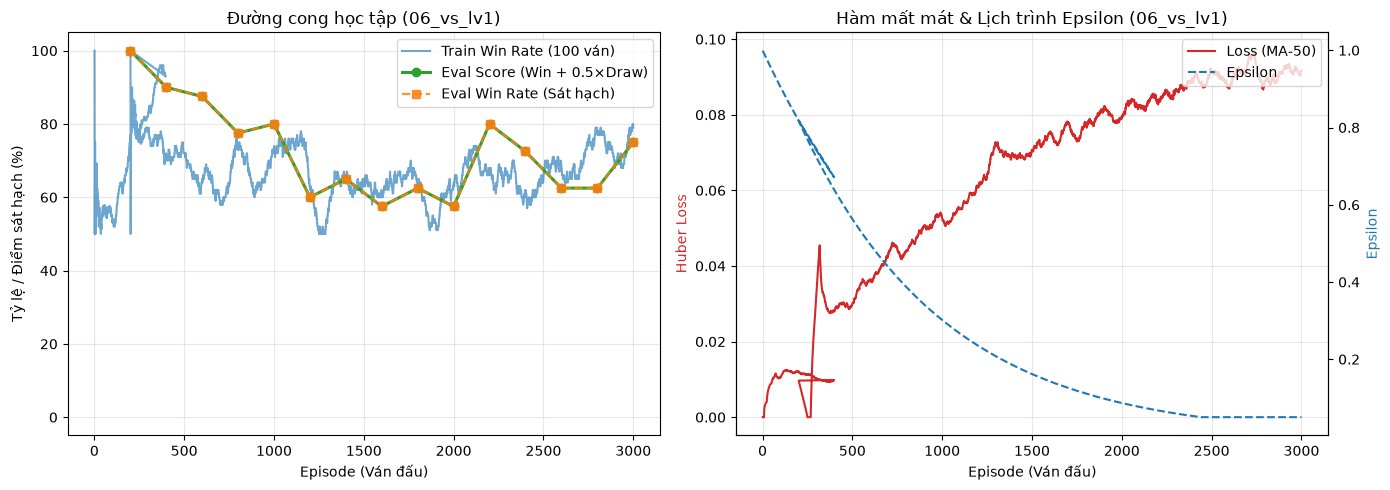

Đã lưu biểu đồ tại: results\figures\06_vs_lv1_learning_curve.png


In [7]:
plot_learning_curve("06_vs_lv1", CFG)

## Cell 6 (Chặng 2a - Bậc thang đệm vs Cấp 2 có 35% random):

*Đối đầu với thuật toán Heuristic (Cấp 2) nhưng có pha thêm 35% xác suất đánh ngẫu nhiên. Giúp giảm độ khó của môi trường để mô hình không bị nản chí và thu hoạch thêm các kịch bản chiến thắng phức tạp.*

In [8]:
train_stage(CFG, "06_vs_lv2_soft")

[INIT] Nạp trọng số nền từ: checkpoints\06_vs_lv1_best.pt


06_vs_lv2_soft:   0%|          | 0/3500 [00:00<?, ?it/s]

[06_vs_lv2_soft] Ep  200/3500 | TrainWR100:  0.00% | EvalScore:  5.00% (W:5%/D:0%, Best:  5.00%) | Loss: 0.00000 | Eps: 0.580 | 0.2m
[06_vs_lv2_soft] Ep  400/3500 | TrainWR100:  3.00% | EvalScore:  5.00% (W:5%/D:0%, Best:  5.00%) | Loss: 0.16430 | Eps: 0.480 | 0.5m
[06_vs_lv2_soft] Ep  600/3500 | TrainWR100:  1.00% | EvalScore:  5.00% (W:5%/D:0%, Best:  5.00%) | Loss: 0.04583 | Eps: 0.398 | 0.9m
[06_vs_lv2_soft] Ep  800/3500 | TrainWR100:  1.00% | EvalScore: 17.50% (W:18%/D:0%, Best: 17.50%) | Loss: 0.02067 | Eps: 0.329 | 1.3m
[06_vs_lv2_soft] Ep 1000/3500 | TrainWR100:  2.00% | EvalScore:  5.00% (W:5%/D:0%, Best: 17.50%) | Loss: 0.01717 | Eps: 0.273 | 1.7m
[06_vs_lv2_soft] Ep 1200/3500 | TrainWR100:  6.00% | EvalScore: 32.50% (W:32%/D:0%, Best: 32.50%) | Loss: 0.01606 | Eps: 0.226 | 2.2m
[06_vs_lv2_soft] Ep 1400/3500 | TrainWR100: 32.00% | EvalScore: 42.50% (W:42%/D:0%, Best: 42.50%) | Loss: 0.01445 | Eps: 0.187 | 2.6m
[06_vs_lv2_soft] Ep 1600/3500 | TrainWR100: 36.00% | EvalScore: 52

WindowsPath('checkpoints/06_vs_lv2_soft_best.pt')

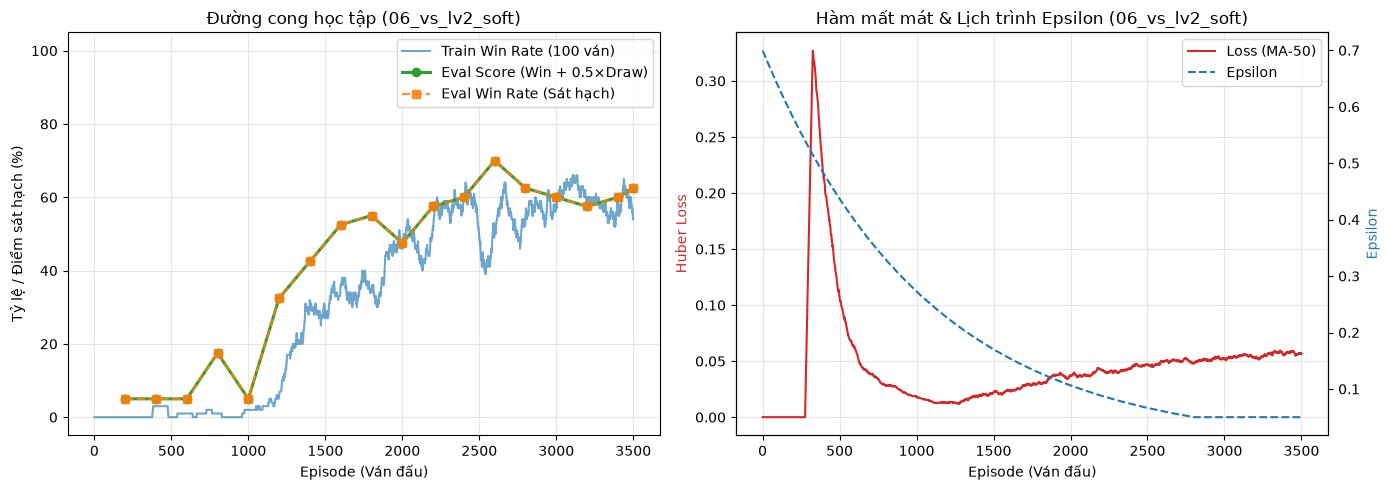

Đã lưu biểu đồ tại: results\figures\06_vs_lv2_soft_learning_curve.png


In [9]:
plot_learning_curve("06_vs_lv2_soft", CFG)

## Cell 7 (Chặng 2b - Đấu Cấp 2 thuần 100%):

*Thử thách thực sự! Mô hình đối kháng trực tiếp với thuật toán Heuristic hoàn chỉnh, bắt buộc phải học cách phòng thủ nghiêm ngặt và tìm sơ hở nhỏ nhất của đối phương để chiến thắng.*

In [10]:
train_stage(CFG, "06_vs_lv2")

[INIT] Nạp trọng số nền từ: checkpoints\06_vs_lv2_soft_best.pt


06_vs_lv2:   0%|          | 0/4000 [00:00<?, ?it/s]

[06_vs_lv2] Ep  200/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00000 | Eps: 0.351 | 0.2m
[06_vs_lv2] Ep  400/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00000 | Eps: 0.308 | 0.4m
[06_vs_lv2] Ep  600/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00705 | Eps: 0.271 | 0.8m
[06_vs_lv2] Ep  800/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00419 | Eps: 0.238 | 1.3m
[06_vs_lv2] Ep 1000/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00155 | Eps: 0.209 | 1.8m
[06_vs_lv2] Ep 1200/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00128 | Eps: 0.183 | 2.4m
[06_vs_lv2] Ep 1400/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00083 | Eps: 0.161 | 2.9m
[06_vs_lv2] Ep 1600/4000 | TrainWR100:  0.00% | EvalScore:  0.00% (W:0%/D:0%, Best:  0.00%) | Loss: 0.00

WindowsPath('checkpoints/06_vs_lv2_best.pt')

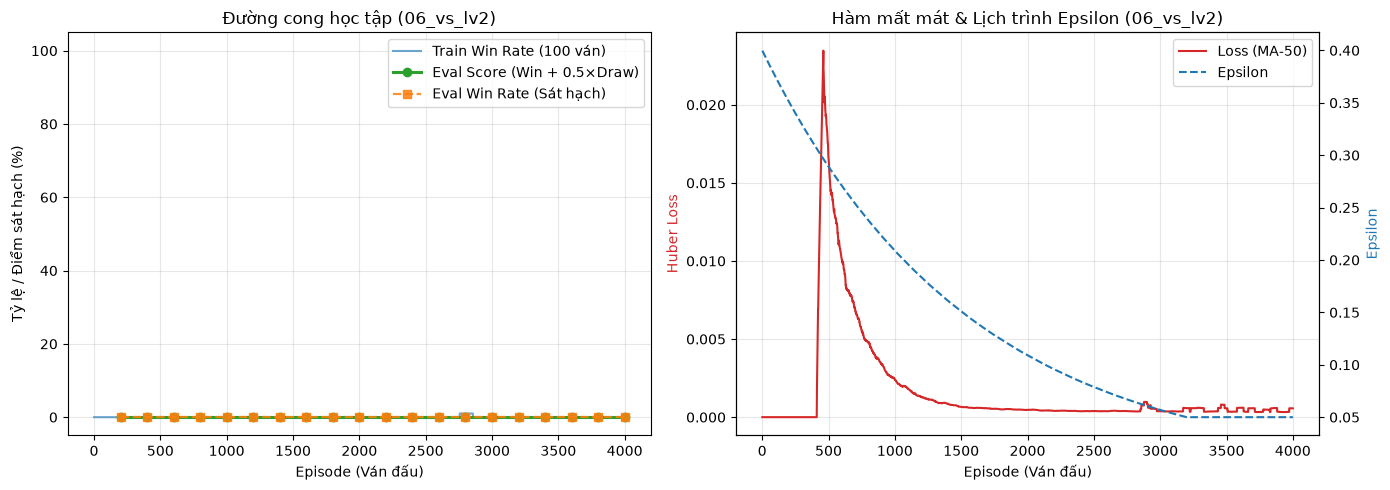

Đã lưu biểu đồ tại: results\figures\06_vs_lv2_learning_curve.png


In [11]:
plot_learning_curve("06_vs_lv2", CFG)

## Cell 8 (Chặng 3 - Self-play, tùy chọn):

*Mô hình tự đấu với chính phiên bản tốt nhất của mình trong quá khứ để liên tục tự nâng cấp tư duy chiến thuật, vượt qua giới hạn của các luật chơi Heuristic thông thường.*

In [12]:
train_stage(CFG, "06_selfplay")

[INIT] Nạp trọng số nền từ: checkpoints\06_vs_lv2_best.pt


06_selfplay:   0%|          | 0/3000 [00:00<?, ?it/s]

[06_selfplay] Ep  200/3000 | TrainWR100: 29.00% | EvalScore: 31.25% (W:62%/D:0% | vsLv2:0%, Best: 31.25%) | Loss: 0.04640 | Eps: 0.258 | 1.0m
[06_selfplay] Ep  400/3000 | TrainWR100: 27.00% | EvalScore: 28.75% (W:57%/D:0% | vsLv2:0%, Best: 31.25%) | Loss: 0.06844 | Eps: 0.223 | 1.6m
[06_selfplay] Ep  600/3000 | TrainWR100: 52.00% | EvalScore: 42.50% (W:85%/D:0% | vsLv2:0%, Best: 42.50%) | Loss: 0.06017 | Eps: 0.192 | 2.2m
[06_selfplay] Ep  800/3000 | TrainWR100: 46.00% | EvalScore: 45.00% (W:90%/D:0% | vsLv2:0%, Best: 45.00%) | Loss: 0.05882 | Eps: 0.165 | 2.7m
[06_selfplay] Ep 1000/3000 | TrainWR100: 50.00% | EvalScore: 42.50% (W:85%/D:0% | vsLv2:0%, Best: 45.00%) | Loss: 0.07319 | Eps: 0.142 | 3.5m
[06_selfplay] Ep 1200/3000 | TrainWR100: 36.00% | EvalScore: 41.25% (W:82%/D:0% | vsLv2:0%, Best: 45.00%) | Loss: 0.09501 | Eps: 0.122 | 4.2m
[06_selfplay] Ep 1400/3000 | TrainWR100: 40.00% | EvalScore: 40.00% (W:80%/D:0% | vsLv2:0%, Best: 45.00%) | Loss: 0.07733 | Eps: 0.105 | 5.1m
[06_se

WindowsPath('checkpoints/06_selfplay_best.pt')

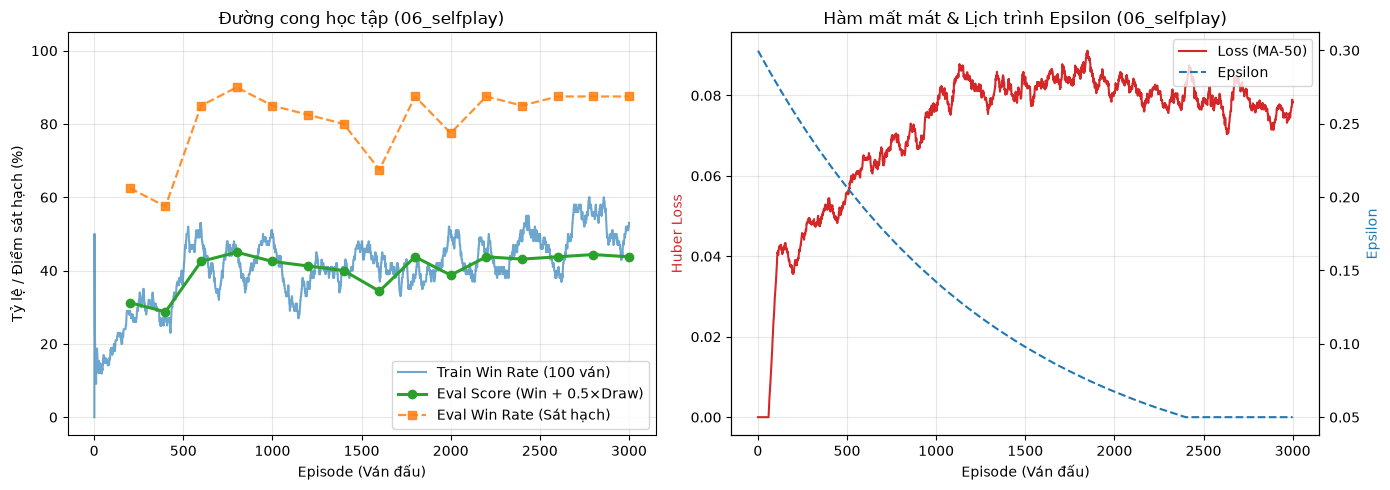

Đã lưu biểu đồ tại: results\figures\06_selfplay_learning_curve.png


In [13]:
plot_learning_curve("06_selfplay", CFG)

## Cell 9 (Ablation 1 - Tắt Reward Shaping để so sánh Sparse vs Shaped):

*Để chứng minh tầm quan trọng của việc thiết lập phần thưởng trung gian (Reward Shaping), chúng ta huấn luyện một mô hình với phần thưởng thưa thớt (Sparse Reward) thuần túy để so sánh tốc độ học tập và hiệu năng cuối cùng.*

In [14]:
train_stage(CFG, "06_vs_lv1", shaping_override=False, run_suffix="_sparse")

06_vs_lv1_sparse:   0%|          | 0/3000 [00:00<?, ?it/s]

[06_vs_lv1_sparse] Ep  200/3000 | TrainWR100: 77.00% | EvalScore: 100.00% (W:100%/D:0%, Best: 100.00%) | Loss: 0.02527 | Eps: 0.779 | 0.6m
[06_vs_lv1_sparse] Ep  400/3000 | TrainWR100: 75.00% | EvalScore: 100.00% (W:100%/D:0%, Best: 100.00%) | Loss: 0.04149 | Eps: 0.607 | 1.8m
[06_vs_lv1_sparse] Ep  600/3000 | TrainWR100: 83.00% | EvalScore: 97.50% (W:98%/D:0%, Best: 100.00%) | Loss: 0.02878 | Eps: 0.473 | 3.8m
[06_vs_lv1_sparse] Ep  800/3000 | TrainWR100: 73.00% | EvalScore: 95.00% (W:95%/D:0%, Best: 100.00%) | Loss: 0.02352 | Eps: 0.368 | 5.7m
[06_vs_lv1_sparse] Ep 1000/3000 | TrainWR100: 80.00% | EvalScore: 92.50% (W:92%/D:0%, Best: 100.00%) | Loss: 0.01980 | Eps: 0.287 | 7.6m
[06_vs_lv1_sparse] Ep 1200/3000 | TrainWR100: 82.00% | EvalScore: 85.00% (W:85%/D:0%, Best: 100.00%) | Loss: 0.01784 | Eps: 0.224 | 9.3m
[06_vs_lv1_sparse] Ep 1400/3000 | TrainWR100: 95.00% | EvalScore: 95.00% (W:95%/D:0%, Best: 100.00%) | Loss: 0.02590 | Eps: 0.174 | 10.8m
[06_vs_lv1_sparse] Ep 1600/3000 | Tr

WindowsPath('checkpoints/06_vs_lv1_sparse_best.pt')

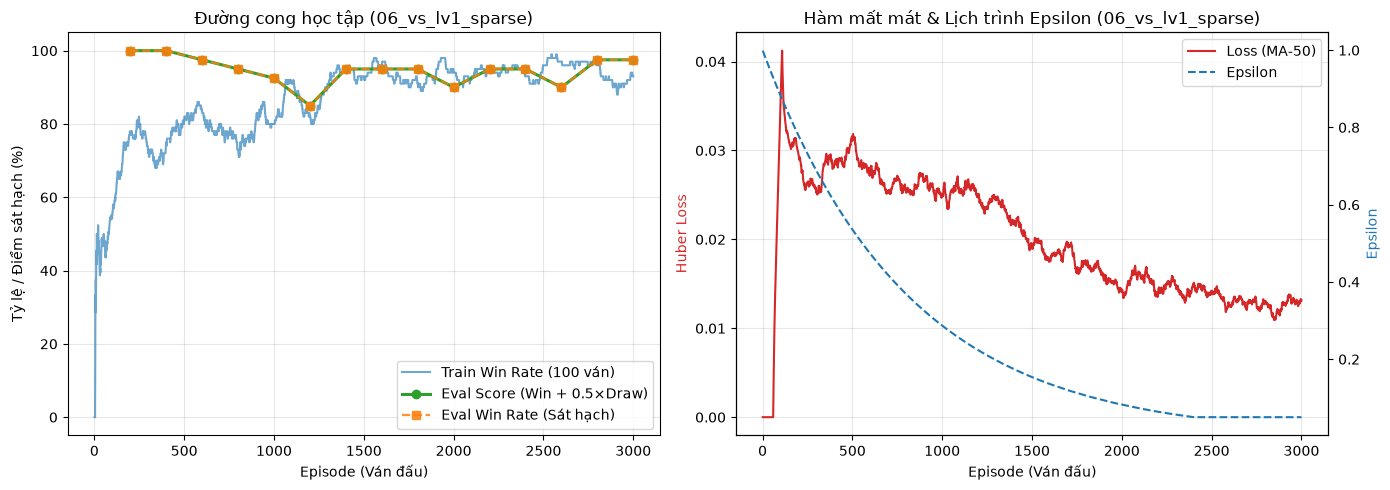

Đã lưu biểu đồ tại: results\figures\06_vs_lv1_sparse_learning_curve.png


In [15]:
plot_learning_curve("06_vs_lv1_sparse", CFG)